# 01 Calidad de datos

**Resultado:** datos limpios en 02_datos/02_Analitico

**Índice**

1. Importar
2. Nulos
3. Valores imposibles
4. Duplicados
5. Categorías
6. Fechas
7. Correcciones
8. Guardar

## 0. Librerías y rutas

In [1]:
# Librerías
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from pathlib import Path
from dotenv import load_dotenv

# Opciones de vista
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

# Rutas del proyecto (el notebook vive en 03_notebooks)
RAIZ = Path.cwd().parent
ORIGINALES = RAIZ / '02_datos' / '01_Originales'
ANALITICO = RAIZ / '02_datos' / '02_Analitico'
RESULTADOS = RAIZ / '06_resultados'

# Variables de entorno (.env): ahí va DATABASE_URL
load_dotenv(RAIZ / '.env')

False

## 1. Importar

Primero una muestra para ver los datos; después la carga completa.

In [2]:
p1g = pd.read_csv(ORIGINALES/'Planta1_Generacion.csv') #planta 1
p2g = pd.read_csv(ORIGINALES/'Planta2_Generacion.csv') #planta 2
p1s = pd.read_csv(ORIGINALES/'Planta1_Sensores.csv') #planta 1 -sensor 1
p2s = pd.read_csv(ORIGINALES/'Planta2_Sensores.csv') #planta 2 -sensor 2

## 1. Nulos e informacion

Cuántos hay por columna y si hay nulos disfrazados (vacío, N/A, 0 sin sentido).

In [ ]:
"""for n in [p1g, p2g, p1s, p2s]:
    n.info()
    print(n.shape)
    display(n.head(3))"""

## 2. Fechas y Regularizacion

* Cambiar los 'Str' de las fecha_hora
* Regularizar los DataSet

In [4]:
p1g['fecha_hora'] = pd.to_datetime(p1g['fecha_hora'], format='%d-%m-%Y %H:%M')
p2g['fecha_hora'] = pd.to_datetime(p2g['fecha_hora'], format='%Y-%m-%d %H:%M:%S')
p1s['fecha_hora'] = pd.to_datetime(p1s['fecha_hora'], format='%Y-%m-%d %H:%M:%S')
p2s['fecha_hora'] = pd.to_datetime(p2s['fecha_hora'], format='%Y-%m-%d %H:%M:%S')

### 2.2 Regularizacion de los DataSet de 15 minutos

In [5]:
# ── Regularidad de fechas ─────────
# comprueba que cada fuente caiga en una rejilla de 15 min sin huecos ni desalineados
filas = []

for nombre, n in [('p1g', p1g), ('p2g', p2g), ('p1s', p1s), ('p2s', p2s)]:
    # marcas únicas ordenadas, para no contar una vez por inversor
    marcas = n['fecha_hora'].drop_duplicates().sort_values()
    # rejilla ideal entre la primera y la última marca
    rejilla = pd.date_range(marcas.min(), marcas.max(), freq='15min')
    # minutos fuera de 0, 15, 30, 45 o con segundos
    desalineadas = ((n['fecha_hora'].dt.minute % 15 != 0) | (n['fecha_hora'].dt.second != 0)).sum()
    filas.append({
        'df': nombre,
        'desde': marcas.min(),
        'hasta': marcas.max(),
        'marcas': len(marcas),
        'rejilla': len(rejilla),
        'faltan': len(rejilla.difference(marcas)),
        'desalineadas': int(desalineadas),
    })

tabla_fechas = pd.DataFrame(filas)
#tabla_fechas

In [6]:
# ── Cobertura por día ─────────
# mide cuántas ventanas trae cada jornada, para separar días sin dato de minutos perdidos
filas = []

for nombre, n in [('p1g', p1g), ('p2g', p2g), ('p1s', p1s), ('p2s', p2s)]:
    # ventanas únicas por día, 96 sería una jornada completa
    por_dia = n.groupby(n['fecha_hora'].dt.date)['fecha_hora'].nunique()
    filas.append({
        'df': nombre,
        'dias': len(por_dia),
        'dias completos': int((por_dia == 96).sum()),
        'min marcas dia': int(por_dia.min()),
        'max marcas dia': int(por_dia.max()),
        'marcas dia incompletos': int((por_dia != 96).sum()),
    })

tabla_dias = pd.DataFrame(filas)
#tabla_dias

In [7]:
# ── Días incompletos ─────────
# lista los días que no llegan a 96 ventanas para ver dónde falta cobertura
for nombre, n in [('p1g', p1g), ('p2g', p2g), ('p1s', p1s), ('p2s', p2s)]:
    por_dia = n.groupby(n['fecha_hora'].dt.date)['fecha_hora'].nunique()
    incompletos = por_dia[por_dia != 96]
    print(nombre, 'días incompletos:', len(incompletos))
    display(incompletos.to_frame('marcas').head(8))

p1g días incompletos: 10


,marcas
fecha_hora,
2020-05-15,93
2020-05-16,88
2020-05-19,93
2020-05-20,76
2020-05-21,65
2020-05-23,89
2020-05-25,95
2020-05-28,90


p2g días incompletos: 5


,marcas
fecha_hora,
2020-05-15,95
2020-05-19,95
2020-05-29,95
2020-06-01,95
2020-06-03,95


p1s días incompletos: 8


,marcas
fecha_hora,
2020-05-15,93
2020-05-16,88
2020-05-19,93
2020-05-20,80
2020-05-21,68
2020-05-23,90
2020-05-29,79
2020-06-03,95


p2s días incompletos: 5


,marcas
fecha_hora,
2020-05-15,95
2020-05-19,95
2020-05-29,95
2020-06-01,95
2020-06-03,95


### 2.3 Analisis Grafico de Tramos/Registros por Fechas y de Tramos/registros por Inverters

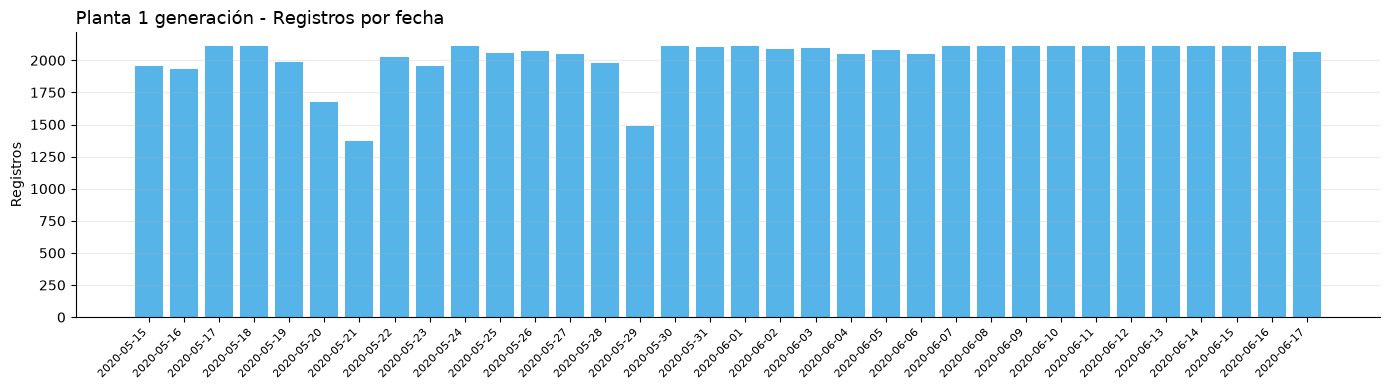

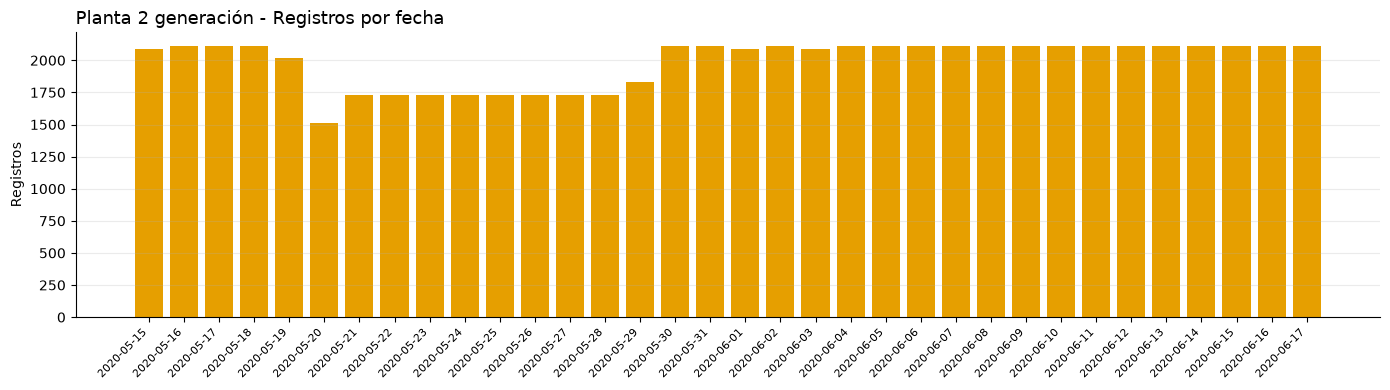

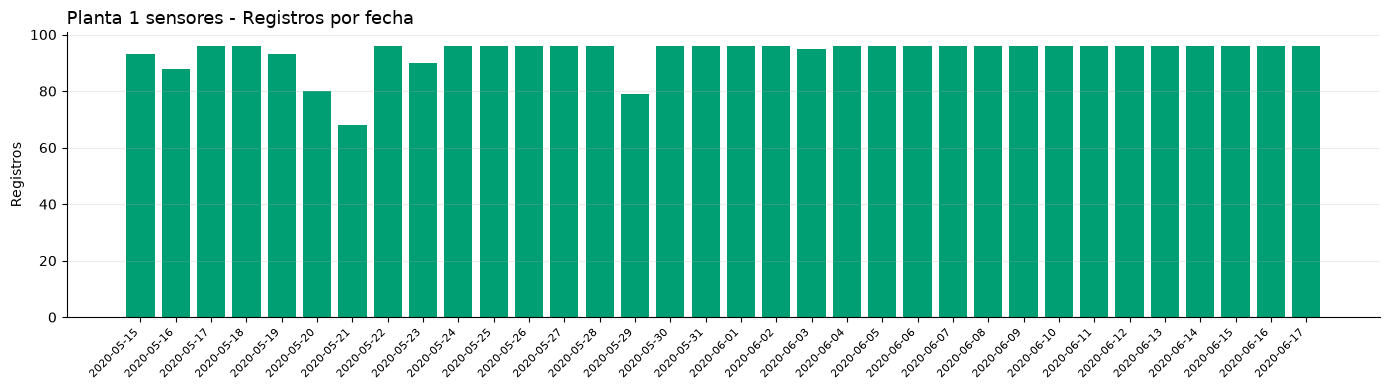

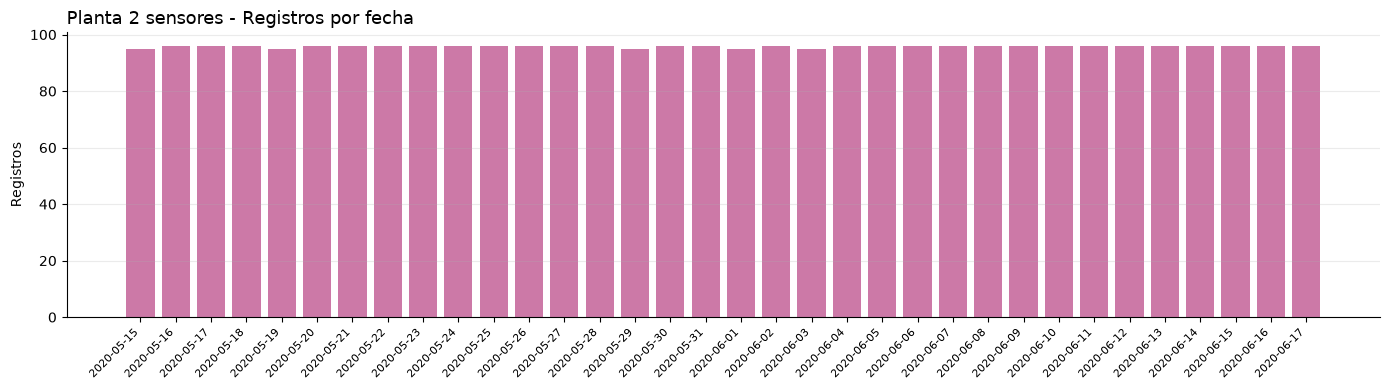

In [8]:
# ── Registros por fecha en las cuatro fuentes ─────────
fuentes = [
    ('Planta 1 generación', p1g, '#56B4E9'),
    ('Planta 2 generación', p2g, '#E69F00'),
    ('Planta 1 sensores', p1s, '#009E73'),
    ('Planta 2 sensores', p2s, '#CC79A7'),
]

for nombre, n, color in fuentes:
    conteo = n.groupby(n['fecha_hora'].dt.date).size()

    # una figura por fuente para que cada una tenga su propio eje
    fig, ax = plt.subplots(figsize=(14, 4))
    ax.bar(conteo.index.astype(str), conteo.values, color=color, width=0.8)

    ax.set_title(f'{nombre} - Registros por fecha', fontsize=13, loc='left')
    ax.set_ylabel('Registros')
    ax.set_xlabel('')
    ax.grid(axis='y', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    plt.xticks(rotation=45, ha='right', fontsize=8)

    plt.tight_layout()
    plt.show()

### Insight 1

Las cuatro fuentes cubren las mismas **34 jornadas**, pero ninguna es regular: **faltan tramos dentro del día**, no días enteros.

Planta 1 es la más afectada: **10 días incompletos** en generación (el 21/05 llega a 65 de 96 ventanas) y **8 días** en sensores (mínimo 68). Planta 2 pierde solo **5 días** en cada fuente y por poco (95 de 96 ventanas).

Todos los saltos que existen son de **15 minutos exactos** y ninguna marca está desalineada, así que el problema es la cobertura, no la rejilla.

Decisión: **no se regulariza** (ver conclusión).

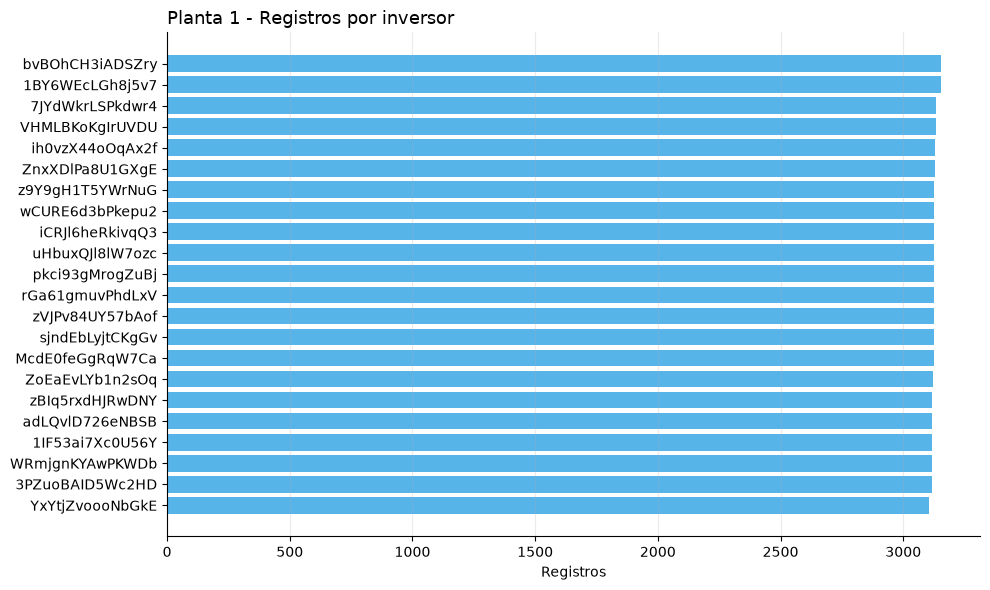

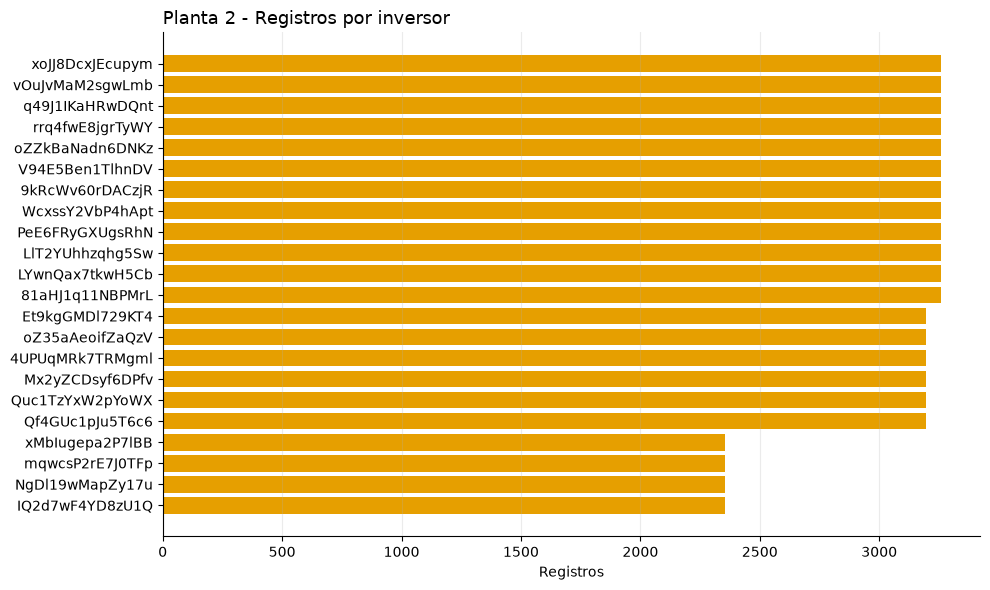

In [9]:
# ── Registros por inversor ─────────
for nombre, n, color in [('Planta 1', p1g, '#56B4E9'), ('Planta 2', p2g, '#E69F00')]:
    # ordenado para ver de un golpe quién trae menos datos
    conteo = n.groupby('id_inversor').size().sort_values()

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.barh(conteo.index, conteo.values, color=color)

    ax.set_title(f'{nombre} - Registros por inversor', fontsize=13, loc='left')
    ax.set_xlabel('Registros')
    ax.set_ylabel('')
    ax.grid(axis='x', alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)

    plt.tight_layout()
    plt.show()

### Insight 2

Planta 1: todos los inversores tienen **los mismos registros**, así que la pérdida es de tramos horarios completos y no de equipos concretos. Todavía no se sabe si falla la captura o el guardado.

Planta 2: **cuatro inversores** acumulan bastante menos datos que el resto, lo que apunta a un problema de esos equipos y no a un hueco general de la planta. Se revisan en el EDA.

## 3. Valores imposibles

comprobar que los sensores y las plancas son unicos en cada csv

In [10]:
p1g['id_planta'].nunique(), p2g['id_planta'].nunique(), p1s['id_planta'].nunique(), p2s['id_planta'].nunique()
#cambio de nombre de las etiquetas de planta 1 y planta 2 para que sean consistentes en todos los datasets
p1g['id_planta'] = p1g['id_planta'].replace(4135001, 'Planta 1')
p2g['id_planta'] = p2g['id_planta'].replace(4136001, 'Planta 2')
p1s['id_planta'] = p1s['id_planta'].replace(4135001, 'Planta 1')
p2s['id_planta'] = p2s['id_planta'].replace(4136001, 'Planta 2')

## 4. Duplicados

Filas repetidas completas y por la clave.

In [11]:
for n in [p1g, p2g, p1s, p2s]:
    print('Duplicados completos:', n.duplicated().sum())


Duplicados completos: 0
Duplicados completos: 0
Duplicados completos: 0
Duplicados completos: 0


## 5. Analiticas



In [12]:
for n in [p1g, p2g, p1s, p2s]:
    resumen = n.describe().T
    display(resumen.style.format('{:,.2f}').background_gradient(cmap='Blues', axis=1))

,count,mean,min,25%,50%,75%,max,std
fecha_hora,"68,778.00",",.2f",",.2f",",.2f",",.2f",",.2f",",.2f",nan
potencia_dc_kw,"68,778.00","3,147.43",0.00,0.00,429.00,"6,366.96","14,471.12","4,036.46"
potencia_ac_kw,"68,778.00",307.80,0.00,0.00,41.49,623.62,"1,410.95",394.40
energia_diaria_kwh,"68,778.00","3,295.97",0.00,0.00,"2,658.71","6,274.00","9,163.00","3,145.18"
energia_total_kwh,"68,778.00","6,978,711.76","6,183,645.00","6,512,002.54","7,146,685.00","7,268,705.91","7,846,821.00","416,271.98"


,count,mean,min,25%,50%,75%,max,std
fecha_hora,"67,698.00",",.2f",",.2f",",.2f",",.2f",",.2f",",.2f",nan
potencia_dc_kw,"67,698.00",246.70,0.00,0.00,0.00,446.59,"1,420.93",370.57
potencia_ac_kw,"67,698.00",241.28,0.00,0.00,0.00,438.22,"1,385.42",362.11
energia_diaria_kwh,"67,698.00","3,294.89",0.00,272.75,"2,911.00","5,534.00","9,873.00","2,919.45"
energia_total_kwh,"67,698.00","658,944,788.42",0.00,"19,964,944.87","282,627,587.00","1,348,495,113.00","2,247,916,295.00","729,667,771.07"


,count,mean,min,25%,50%,75%,max,std
fecha_hora,"3,182.00",",.2f",",.2f",",.2f",",.2f",",.2f",",.2f",nan
temperatura_ambiente_c,"3,182.00",25.53,20.40,22.71,24.61,27.92,35.25,3.35
temperatura_modulo_c,"3,182.00",31.09,18.14,21.09,24.62,41.31,65.55,12.26
irradiacion_wh_m2,"3,182.00",0.23,0.00,0.00,0.02,0.45,1.22,0.30


,count,mean,min,25%,50%,75%,max,std
fecha_hora,"3,259.00",",.2f",",.2f",",.2f",",.2f",",.2f",",.2f",nan
temperatura_ambiente_c,"3,259.00",28.07,20.94,24.60,26.98,31.06,39.18,4.06
temperatura_modulo_c,"3,259.00",32.77,20.27,23.72,27.53,40.48,66.64,11.34
irradiacion_wh_m2,"3,259.00",0.23,0.00,0.00,0.02,0.44,1.10,0.31


Parece haber un decimal corrido en la Potencia DC en la Planta 1 porque la eficiencia esta por debajo del 10%. En la Planta 2 parece una relacion mas logica.

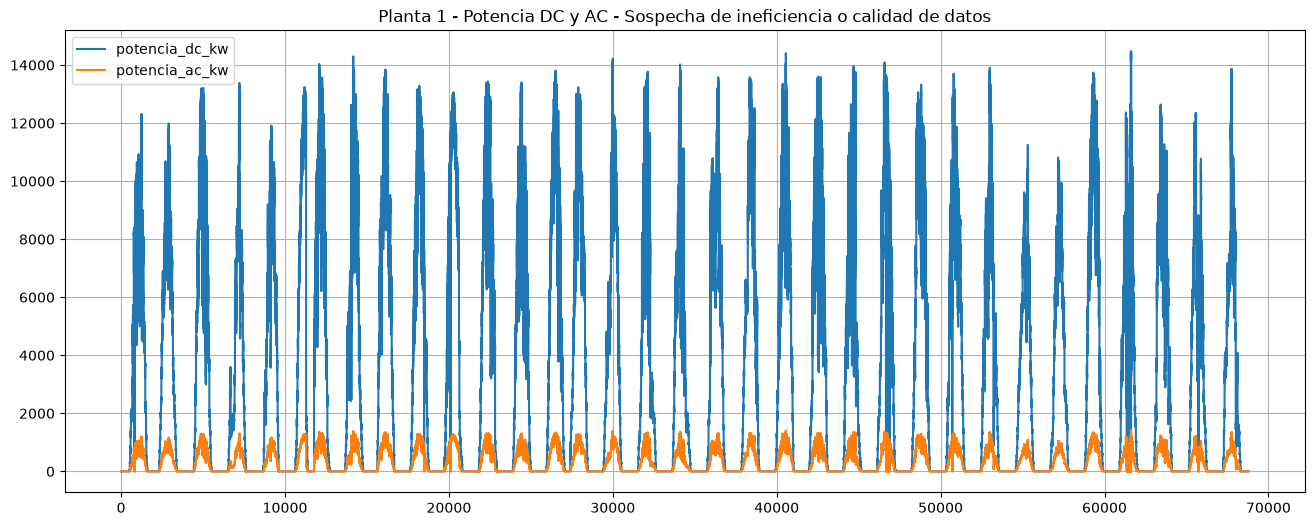

In [13]:
p1g[['potencia_dc_kw', 'potencia_ac_kw']].plot(figsize=(16, 6), title='Planta 1 - Potencia DC y AC', grid=True)
plt.title('Planta 1 - Potencia DC y AC - Sospecha de ineficiencia o calidad de datos');

### Insight 3

La **potencia_dc_kw** de planta 1 está desplazada un factor de 10: 3.147 kW de media frente a 308 kW de AC, un ratio de conversión del 10% que no existe en ningún inversor real.

Es un **error de decimal**, no una ineficiencia. Decisión: dividir **potencia_dc_kw entre 10** y recalcular el ratio, que queda en el **98%**, igual que en planta 2.

## 6. Correcciones

dividir por 10 la potencia DC

In [14]:
p1g['potencia_dc_kw'] = p1g['potencia_dc_kw']/10


## 7. Guardar

Los datos limpios a 02_datos/02_Analitico.

In [15]:
p1g.to_pickle(ANALITICO / 'Planta1_Generacion.pkl')
p2g.to_pickle(ANALITICO / 'Planta2_Generacion.pkl')
p1s.to_pickle(ANALITICO / 'Planta1_Sensores.pkl')
p2s.to_pickle(ANALITICO / 'Planta2_Sensores.pkl')

## Conclusión

1. Las cuatro fuentes cubren **34 jornadas**, pero ninguna es regular. Faltan tramos dentro del día: planta 1 tiene **10 días incompletos** (en tramos de 15min) en generación y **8** en sensores, con mínimos de 65 y 68 ventanas de 96; planta 2 pierde **5 días** en cada fuente y solo 1 o 2 ventanas por día. Todos los saltos son de 15 minutos exactos, así que el problema es la cobertura, no la rejilla.

2. En planta 1 la pérdida **no viene de los inversores**, todos traen los mismos registros y faltan tramos completos. En planta 2 sí hay **cuatro inversores** por debajo del resto, que pasan al EDA.

3. La potencia DC de planta 1 estaba **10 veces por encima** de la AC. Tras dividirla entre 10, la conversión DC a AC queda en **98%**, igual que en planta 2.

4. **No se regulariza la serie.** Rellenar ventanas obliga a interpolar y a inventar lecturas, lo que sesga el análisis y aplana patrones reales como nubarrones, caídas de generación o paradas de inversor. La siguiente fase trabaja con las ventanas observadas y compara siempre los mismos días.
5. Esta decisión cambiaría con un **modelo multivariante por planta**, por ejemplo para predecir la temperatura del módulo. Ahí la regularización sería obligatoria, porque los retardos y ventanas del modelo exigen saltos de 15 minutos sin huecos.

6. Pasa a integración un dataset con la potencia DC corregida, **sin imputar** y con la lista de días incompletos y de los cuatro inversores marcada para revisar.